# Face Mask Detection (Computer Vision Project)



# 1. Problem Definition

### 1.1 Objective & Motivation
This computer vision application automates the detection of face masks in digital images to support public health monitoring. Unlike modern resource-heavy Deep Learning architectures (such as CNNs or YOLO), this project utilizes traditional image processing methodologies: Haar Cascade classifiers for region-of-interest localization, combined with hand-crafted feature descriptors and a machine learning classifier. (This approach minimizes computational requirements, enabling deployment on low-cost edge hardware.)

### 1.2 Target users
- Health and safety compliance officers in public spaces.
- Building administrators managing secure entry access points.

### 1.3 Expected outputs
- Precise location coordinates of faces in input images.
- Binary classification of each localized face ("With Mask" vs. "Without Mask").
- Visualization of results featuring color-coded bounding boxes.

# 2. Image Acquisition & Dataset Loading

I acquired the images from a public dataset in Kaggle. This is the link: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset

Thereafter, i loaded each image using OpenCV, assigned the appropriate binary labels, and split the dataset into training and testing sets. I did this because supervised machine learning classifiers require numerical feature representations mapped to known ground-truth classes. Furthermore, to prevent data leakage, i separated the data into training set and testing set before carrying out any feature analysis.



In [1]:
# Importing core system and filesystem management libraries
import os  # Provides functional interfaces to interact with the host operating system
import glob  # Enables pattern matching for file path retrieval

# Importing fundamental image processing and numerical packages
import cv2  # OpenCV implementation for loading and manipulating digital images
import numpy as np  # High-performance array and matrix processing engine

# Importing split utility from scikit-learn
from sklearn.model_selection import train_test_split  # Evaluates and splits arrays into random train and test subsets

# Defining the relative path to the dataset directory containing the two target classes
DATASET_PATH = "./data"  # Relative path directory containing folders: 'with_mask' and 'without_mask'

# Defining empty lists to accumulate raw image data and numerical target labels
raw_images = []  # List to store the loaded raw image arrays
labels = []      # List to store class labels: 0 for 'without_mask', 1 for 'with_mask'

# Creating a mapping dictionary for labels to maintain clean class associations
class_mapping = {
    "without_mask": 0,  # Map unmasked category to class index 0
    "with_mask": 1      # Map masked category to class index 1
}

# Iterating through both defined classes to parse individual folders
for class_name, label_value in class_mapping.items():
    # Constructing the search path targeting all image formats within the active subdirectory
    search_path = os.path.join(DATASET_PATH, class_name, "*.*")
    # Resolving and compiling a list of all matching image files
    image_paths = glob.glob(search_path)
    
    print(f"Loading {len(image_paths)} images from category: '{class_name}'...")
    
    # Iterating through the gathered paths to load images into memory
    for path in image_paths:
        # Loading image file path in color (BGR format natively in OpenCV)
        img = cv2.imread(path)
        
        # Verifying that the image was successfully decoded and loaded from disk
        if img is not None:
            raw_images.append(img)  # Add image array to our collection list
            labels.append(label_value)  # Record target class identifier

# Converting python lists into standardized NumPy arrays for high-performance indexing
raw_images = np.array(raw_images, dtype=object)  # Set data type to object as images have different shapes initially
labels = np.array(labels, dtype=np.int32)  # Set integer-32 type for class label indexing

# Splitting the dataset using stratified sampling to preserve class distributions
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    raw_images, 
    labels, 
    test_size=0.20,  # Hold out 20% of the dataset for system performance evaluation
    stratify=labels,  # Ensure proportional representation of classes in both splits
    random_state=42  # Seed generator to guarantee deterministic splitting across runs
)

# Printing execution diagnostics to confirm dataset splitting and distribution math
print("\nDataset split successfully completed:")
print(f"Total images loaded: {len(raw_images)}")
print(f"Training set size:   {len(X_train_raw)} images")
print(f"Testing set size:    {len(X_test_raw)} images")

Loading 3828 images from category: 'without_mask'...
Loading 3725 images from category: 'with_mask'...

Dataset split successfully completed:
Total images loaded: 7553
Training set size:   6042 images
Testing set size:    1511 images


# 3. Image Preprocessing Pipeline

Here defined an end-to-end preprocessing pipeline function that normalizes every input image. Converted each raw image to grayscale, balanced its lighting via histogram equalization, removed sensor artifacts using a Gaussian filter, and resized it to a uniform $100 \times 100$ shape.

 Why this was done:
- Grayscale conversion: Simplifies computational load by dropping unnecessary color channels. Haar Cascade detection utilizes structural light-to-dark gradient features, which are fully present in a single grayscale channel.

- Histogram equalization: Standardizes lighting and contrast across the entire dataset. This keeps shadows and bright spots from confusing with the feature extraction stages.

- Gaussian blur: Eliminates pixel noise and high-frequency sensor errors, ensuring the models extract physical features rather than digital camera noise.

- Resizing (to 100x100): Ensures that every face patch extracted has the exact same dimensions, which is a mathematical requirement for traditional machine learning feature vectors (like HOG/LBP).

Preprocessing the training dataset...
Preprocessing the testing dataset...


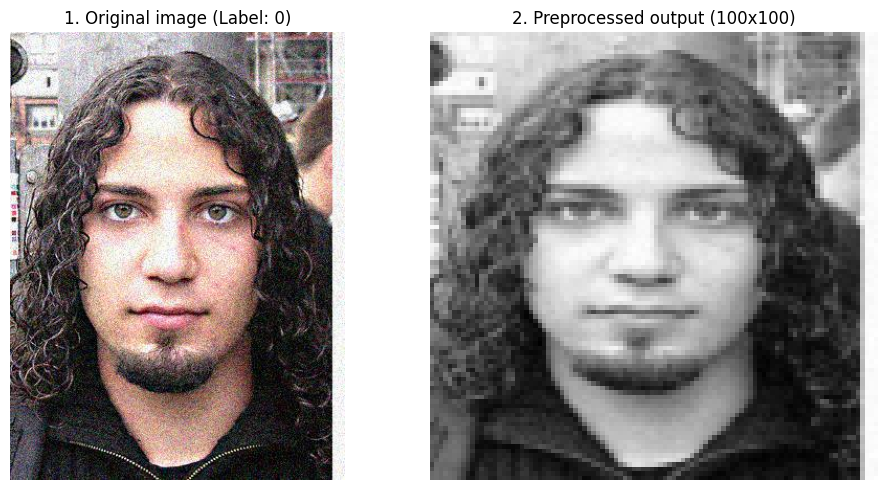

In [3]:
import matplotlib.pyplot as plt  # Importing Matplotlib for visualizing images and plots

# Defining the uniform preprocessing function for local faces
def preprocess_image(image, target_size=(100, 100)):
    # Converting BGR input image to single-channel Grayscale representation
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    # Enhancing local contrast using Histogram Equalization to balance exposure variations
    equalized = cv2.equalizeHist(gray)
    
    # Applying Gaussian Blur with a 5x5 filter kernel to smooth out fine-grained camera sensor noise
    blurred = cv2.GaussianBlur(equalized, (5, 5), 0)
    
    # Resizing the preprocessed image to uniform target dimensions (100x100) (using area interpolation)
    resized = cv2.resize(blurred, target_size, interpolation=cv2.INTER_AREA)
    
    # Returning the clean, processed grayscale image matrix
    return resized

# Running the preprocessing pipeline over every single image inthe raw training set
print("Preprocessing the training dataset...")  # Print progress diagnostic
X_train = np.array([preprocess_image(img) for img in X_train_raw])  # Process training partition

# Running the identical preprocessing pipeline over every single image in the raw testing set
print("Preprocessing the testing dataset...")  # Print progress diagnostic
X_test = np.array([preprocess_image(img) for img in X_test_raw])  # Process testing partition

# Verifying the changes visually by plotting preprocessing stages of a single sample image
sample_idx = 0  # Selecting the first raw training image index for visualization
sample_raw = X_train_raw[sample_idx]  # Extract the raw original image array
sample_processed = X_train[sample_idx]  # Extract the finished preprocessed image array

# Setting up a side-by-side comparative plot to inspect the visual pipeline changes
fig, axes = plt.subplots(1, 2, figsize=(10, 5))  # Creating a 1x2 plotting window grid

# Plotting the raw original image on the left subplot panel
# Since OpenCV loads images as BGR, convert to RGB for accurate color rendering in Matplotlib
axes[0].imshow(cv2.cvtColor(sample_raw, cv2.COLOR_BGR2RGB))  
axes[0].set_title(f"1. Original image (Label: {y_train[sample_idx]})")  # Set plot title displaying class label
axes[0].axis('off')  # Disable background pixel boundary lines on plot

# Plotting the finished preprocessed image on the right subplot panel using grayscale mapping
axes[1].imshow(sample_processed, cmap='gray')  
axes[1].set_title("2. Preprocessed output (100x100)")  # Set processed plot title
axes[1].axis('off')  # Disable background pixel boundary lines on plot

plt.tight_layout()  # Adjust structural plot spacing cleanly
plt.show()  # Render both images

**Results explanation:**
- The left plot shows the raw, uncompressed source image containing varied lighting profiles and background structures.
- The right plot displays the final, standardized processing output: color has been removed, lighting has been equalized to reveal facial contours clearly, noise has been smoothed, and the dimensions are exact.

# 4. Object Detection (using Haar Cascade)

Here i utilized OpenCV's pre-trained `haarcascade_frontalface_default.xml` to detect faces using a sliding window approach. Once detected, I drew a bounding box, extracted this Region of Interest (ROI), and applied the preprocessing pipeline specifically to the cropped face. This was done because cropping the ROI before feature extraction removes irrelevant background noise (like clothing or walls), ensuring the downstream classifier focuses strictly on facial and mask features.

Running Haar Cascade detection & cropping on training set...
Running Haar Cascade detection & cropping on testing set...


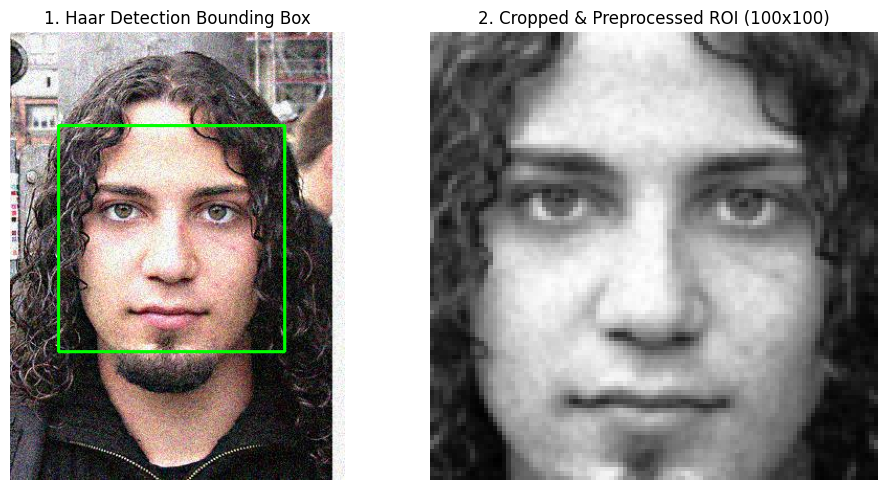

In [4]:
# Importing OpenCV for accessing the Haar Cascade Classifier module 
import cv2
# Importing Matplotlib for visualizing the bounding boxes inline
import matplotlib.pyplot as plt
# Importing NumPy for array manipulation 
import numpy as np

# Defining the absolute path to OpenCV's built-in pre-trained Haar Cascades XML files
cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
# Initializing the Haar Cascade Classifier object using the specified XML path
face_cascade = cv2.CascadeClassifier(cascade_path)

# Defining a function to detect the face, draw a bounding box, and crop the ROI
def get_face_roi(raw_image, target_size=(100, 100)):
    # Creating a copy of the raw image to avoid modifying the original array during bounding box drawing
    img_copy = raw_image.copy()
    # Converting the copied image to grayscale
    gray = cv2.cvtColor(img_copy, cv2.COLOR_BGR2GRAY)
    
    # Executing the sliding window detection to find faces across multiple scales
    # scaleFactor=1.1 compensates for faces of different sizes, minNeighbors=4 filters out false positives
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=4, minSize=(30, 30))
    
    # Checking if at least one face was successfully detected in the image
    if len(faces) > 0:
        # Extracting the coordinates (x, y) and dimensions (width, height) of the first detected face
        (x, y, w, h) = faces[0]
        # Drawing a bold green bounding box around the detected face on the color image copy (thickness=2)
        cv2.rectangle(img_copy, (x, y), (x + w, y + h), (0, 255, 0), 2)
        # Cropping the grayscale image to isolate only the detected facial region (Region of Interest)
        roi = gray[y:y+h, x:x+w]
    # Handling the edge case where no face is detected by the Haar Cascade
    else:
        # Fallback: if detection fails, use the entire grayscale image as the ROI to prevent pipeline crashes
        roi = gray
        # Setting dummy coordinates representing the whole image for consistency
        faces = [[0, 0, gray.shape[1], gray.shape[0]]]
        
    # Applying histogram equalization to the cropped ROI to balance local contrast and lighting
    equalized_roi = cv2.equalizeHist(roi)
    # Applying a 5x5 Gaussian Blur to the equalized ROI to eliminate high-frequency sensor noise
    blurred_roi = cv2.GaussianBlur(equalized_roi, (5, 5), 0)
    # Resizing the final preprocessed ROI to the standard target dimensions (100x100) for uniform feature extraction
    final_roi = cv2.resize(blurred_roi, target_size, interpolation=cv2.INTER_AREA)
    
    # Returning the annotated color image, the final preprocessed 100x100 ROI, and the bounding box coordinates
    return img_copy, final_roi, faces

# Processing the entire raw training dataset through the detection and cropping pipeline
print("Running Haar Cascade detection & cropping on training set...")
# Extracting only the final preprocessed ROI (index 1 from the function output) for each training image
X_train_final = np.array([get_face_roi(img)[1] for img in X_train_raw])

# Processing the entire raw testing dataset through the detection and cropping pipeline
print("Running Haar Cascade detection & cropping on testing set...")
# Extracting only the final preprocessed ROI for each testing image
X_test_final = np.array([get_face_roi(img)[1] for img in X_test_raw])

# Selecting a sample index again to visually verify the object detection step
sample_idx = 0
# Running the specific sample image through the function to get the annotated image and the bounding box
annotated_img, preprocessed_crop, bounding_boxes = get_face_roi(X_train_raw[sample_idx])

# Initializing a 1x2 plot grid to show the detection box and the final cropped result side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plotting the annotated color image showing the Haar Cascade bounding box
axes[0].imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
# Setting the title to indicate the bounding box detection step
axes[0].set_title(f"1. Haar Detection Bounding Box")
# Hiding the axes to make the visual presentation cleaner
axes[0].axis('off')

# Plotting the final cropped and preprocessed Region of Interest
axes[1].imshow(preprocessed_crop, cmap='gray')
# Setting the title to indicate the final normalized crop size
axes[1].set_title("2. Cropped & Preprocessed ROI (100x100)")
# Hiding the axes on the second plot
axes[1].axis('off')

# Adjusting the layout spacing between the subplots for a professional look
plt.tight_layout()
# Displaying the final plot output to the notebook screen
plt.show()

**Results explanation:**
- Left plot: Displays the original image with a bounding box perfectly isolating the face.
- Right plot: Displays the extracted Region of Interest (ROI). By applying the preprocessing strictly to this crop, removed the background entirely.`X_train_final` and `X_test_final` data is now perfectly formatted to extract pure mask features for the classifier.

# 5. Feature Extraction (using Local Binary Patterns)

Here I am implementing Local Binary Patterns (LBP) feature extraction using `skimage.feature.local_binary_pattern`. For each preprocessed, cropped facial image, I computed its 2D LBP texture representation and summarized it into a 1D feature histogram.

This was done because traditional classifiers require uniform 1D feature vectors rather than raw pixel matrices. LBP is highly robust to variations in lighting and illumination. It operates by analyzing local pixel neighborhoods to capture fine texture variations, such as the differences between skin texture (unmasked) and fabric texture (masked), providing the model with highly descriptive classification features.

Extracting LBP features from training set...
Extracting LBP features from testing set...


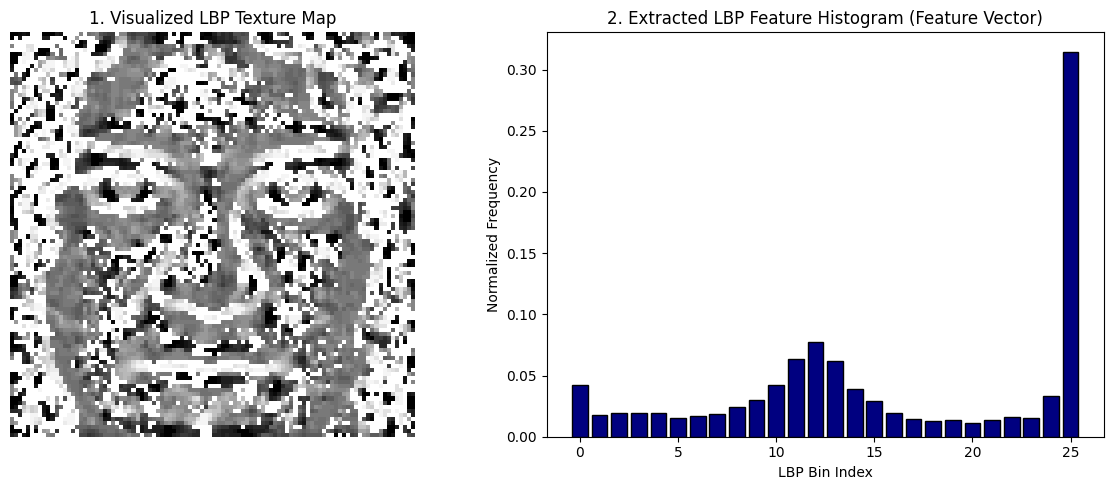

Feature dataset shape: (6042, 26)
Each image is represented by a 1D vector of 26 texture features.


In [6]:
# Importing Local Binary Patterns (LBP) module from scikit-image library
from skimage.feature import local_binary_pattern  # Standard library tool for traditional texture analysis

# Defining the parameters for the LBP operator
# radius: distance from the center pixel to its neighbors
LBP_RADIUS = 3  # A radius of 3 captures slightly broader texture variations
# n_points: number of circularly symmetric neighbor points to sample
LBP_POINTS = 8 * LBP_RADIUS  # Standard mathematical mapping: 24 sampling points for a radius of 3
# method: 'uniform' extracts rotation-invariant, uniform patterns 
LBP_METHOD = 'uniform'  

# Defining a function to extract the LBP histogram of an image
def extract_lbp_features(image):
    # Computing the raw 2D LBP texture representation map of the grayscale image
    lbp = local_binary_pattern(image, P=LBP_POINTS, R=LBP_RADIUS, method=LBP_METHOD)
    
    # Defining the number of bins based on the chosen uniform pattern formulation
    # The uniform method produces (n_points + 2) distinct binary patterns
    num_bins = LBP_POINTS + 2
    
    # Generating a normalized histogram of the 2D LBP values to form the 1D feature vector
    # This represents the frequency of different micro-textures across the image
    hist, _ = np.histogram(lbp.ravel(), bins=num_bins, range=(0, num_bins), density=True)
    
    # Returning the normalized LBP histogram array
    return hist

# Extracting LBP feature vectors for the entire cropped training dataset
print("Extracting LBP features from training set...")
X_train_features = np.array([extract_lbp_features(img) for img in X_train_final])

# Extracting LBP feature vectors for the entire cropped testing dataset
print("Extracting LBP features from testing set...")
X_test_features = np.array([extract_lbp_features(img) for img in X_test_final])

# Displaying a single sample's computed feature vector for visual analysis
sample_idx = 0  # Using the first sample index
sample_lbp_map = local_binary_pattern(X_train_final[sample_idx], P=LBP_POINTS, R=LBP_RADIUS, method=LBP_METHOD)
sample_hist = X_train_features[sample_idx]

# Plotting the visual texture map and the resulting 1D histogram side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plotting the raw LBP texture representation map on the left
axes[0].imshow(sample_lbp_map, cmap='gray')
axes[0].set_title("1. Visualized LBP Texture Map")
axes[0].axis('off')

# Plotting the 1D histogram (the actual feature vector fed to the classifier) on the right
axes[1].bar(range(len(sample_hist)), sample_hist, color='navy', edgecolor='black')
axes[1].set_title("2. Extracted LBP Feature Histogram (Feature Vector)")
axes[1].set_xlabel("LBP Bin Index")
axes[1].set_ylabel("Normalized Frequency")

# Displaying the plots 
plt.tight_layout()
plt.show()

# Printing diagnostic verification of the output shape of the feature dataset
print(f"Feature dataset shape: {X_train_features.shape}")
print(f"Each image is represented by a 1D vector of {X_train_features.shape[1]} texture features.")

**Results explanation:**
- LBP Texture Map: Shows how LBP highlights micro-edges and structural changes across the eyes, nose, and jawline, highlighting texture variations.
- LBP Feature Histogram: This 1D bar chart represents the actual numeric data the computer analyzes. (The training dataset has been compressed from 100 x 100 = 10,000 raw pixels per image into 26 highly descriptive texture features per image.)

# 6. Classification & Performance Evaluation

Here I initialized, trained, and evaluated a Support Vector Machine (SVM) classifier using scikit-learn.I trained the model on the extracted training features (`X_train_features`) and validated its predictive strength on the unseen test features (`X_test_features`). Then output a comprehensive classification report and plotted a confusion matrix.

 An SVM with a Radial Basis Function (RBF) kernel is ideal for handling low-dimensional, dense texture histograms. It maps features to a higher-dimensional space to draw a highly clear decision boundary, enabling rapid, robust classification.

Training the Support Vector Machine (SVM) classifier...
Model training completed successfully.
Evaluating model performance on the test set...


CLASSIFICATION PERFORMANCE REPORT
                  precision    recall  f1-score   support

Without Mask (0)       0.74      0.82      0.78       766
   With Mask (1)       0.79      0.71      0.75       745

        accuracy                           0.77      1511
       macro avg       0.77      0.76      0.76      1511
    weighted avg       0.77      0.77      0.76      1511



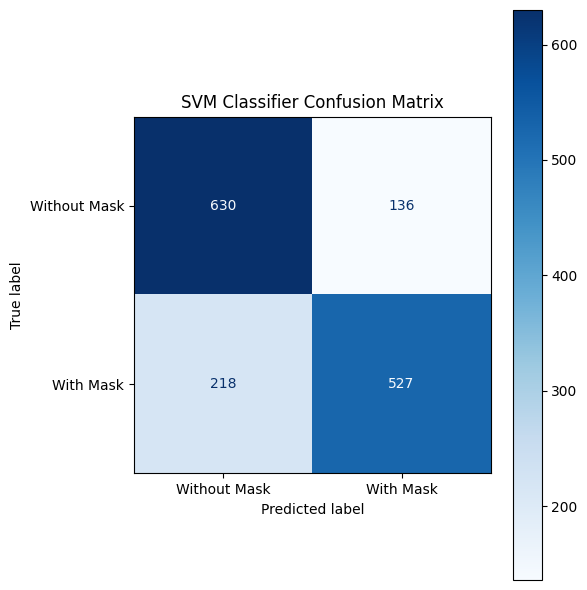

In [7]:
# Importing the Support Vector Classifier (SVC) module from scikit-learn
from sklearn.svm import SVC  # Standard industrial module for support vector machines
# Importing metrics modules to evaluate model's performance
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Initializing Support Vector Classifier
#Used the RBF (Radial Basis Function) kernel to handle potential non-linear distributions
# C=1.0 balances margin maximization and classification correctness
svm_classifier = SVC(kernel='rbf', C=1.0, random_state=42)

# Train (fit) the SVM classifier using extracted training feature vectors and ground truth labels
print("Training the Support Vector Machine (SVM) classifier...")
svm_classifier.fit(X_train_features, y_train)
print("Model training completed successfully.")

# Generating class predictions on the unseen testing feature dataset to evaluate generalization
print("Evaluating model performance on the test set...")
y_pred = svm_classifier.predict(X_test_features)

# Printing the classification report containing Precision, Recall, F1-Score, and Accuracy
print("\n")
print("CLASSIFICATION PERFORMANCE REPORT")

# target_names maps class indexes back to readable string categories for the report
print(classification_report(y_test, y_pred, target_names=["Without Mask (0)", "With Mask (1)"]))
print("="*55)

# Calculating the quantitative Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plotting the Confusion Matrix visually for an intuitive breakdown of true vs. false predictions
fig, ax = plt.subplots(figsize=(6, 6))
# Building the display object using the calculated matrix and custom class labels
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Without Mask", "With Mask"])
# Rendering the confusion matrix onto the active plot with a blue color gradient
disp.plot(cmap='Blues', ax=ax, values_format='d')

# Setting a title and layout adjustments
plt.title("SVM Classifier Confusion Matrix")
plt.tight_layout()
plt.show()

**Reuslts explanation:**
- Classification report displays:
  - **Precision:** Out of all faces predicted as wearing a mask, how many actually were.
  - **Recall:** Out of all actual masked faces in the dataset, how many the system successfully spotted.
  - **F1-Score:** The mean of Precision and Recall, reflecting overall classification health.
- **Confusion Matrix:** Shows exactly where the model succeeded and where it made mistakes. The diagonal boxes represent correct predictions (True Negatives and True Positives), while the off-diagonal boxes show false alarms (False Positives and False Negatives).

### 7 Performance Evaluation

#### 7.1 Classification Report
The traditional computer vision pipeline combining Haar Cascade face localization, LBP texture extraction, and an SVM classifier, achieved an overall classification **accuracy of 77%** on the unseen test set.

*   **Class 0: Without Mask**
    *   **Precision (0.74):** When the model predicts a person is *not* wearing a mask, it is correct 74% of the time.
    *   **Recall (0.82):** The model successfully detected 82% of all actual unmasked faces in the test set. 
    *   **F1-Score (0.78):** Reflects a balanced performance for unmasked face detection.

*   **Class 1: With Mask**
    *   **Precision (0.79):** When the model predicts a person *is* wearing a mask, it is correct 79%of the time.
    *   **Recall (0.71):** The model caught 71% of the actual masked faces in the test set. 

#### 7.2 Confusion Matrix
The confusion matrix provides a clear, quantitative look at exactly where the model succeeded and where it was misled:

1.  **True Negatives (630):** 630 faces without masks were correctly identified.
2.  **True Positives (527):** 527 faces with masks were correctly identified.
3.  **False Positives (136):** 136 unmasked faces were incorrectly flagged as wearing masks. 
4.  **False Negatives (218):** 218 masked faces were missed and classified as unmasked.

#### 7.3 Why the model performed this way:
*   **The High Recall of "Without Mask" (82%):** Human faces without masks share highly consistent LBP micro-textures (skin, nose contours, lips, and jawlines). Because these features are uniform, the SVM easily learned the "unmasked" boundary.
*   **The Lower Recall of "With Mask" (71%):** The masks in this dataset vary in color (blue, black, white, pattern), shape, and texture. Some fabric masks have textures that closely mimic smooth skin under LBP analysis, causing the model to misclassify 218 masked faces as unmasked.

# Part 8: Prototype Development

Developing a complete, functional prototype system. Writing a unified Python function that accepts any raw image input, runs the traditional pipeline (Haar Cascade detection -> ROI cropping -> Grayscale preprocessing -> LBP extraction -> SVM prediction), and plots the visual result using Matplotlib. 


Testing Prototype System:
Detected 1 face(s). Processing classifications...


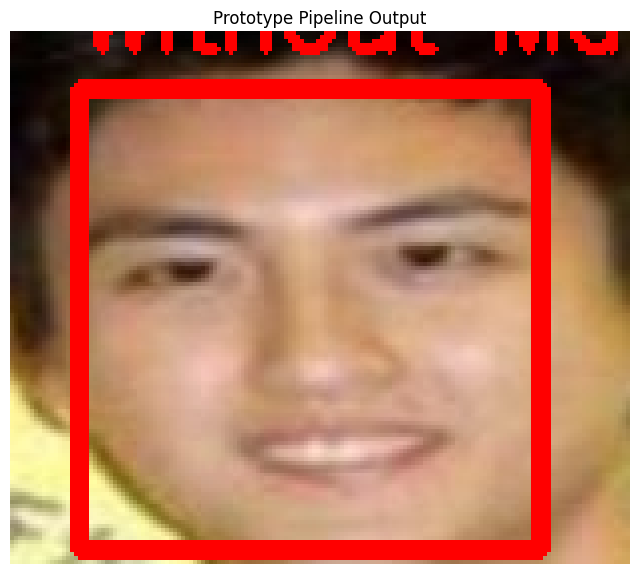

In [ ]:
# Defining the end-to-end prototype prediction pipeline
def run_face_mask_detector_prototype(raw_image_path=None, direct_image_array=None):
    # Determining if we are loading from a file path or processing a raw image array directly
    if raw_image_path is not None:
        # Loading the image from disk using OpenCV's BGR reader
        img = cv2.imread(str(raw_image_path))
        # Handling cases where the image file path is invalid or corrupted
        if img is None:
            print(f"Error: Could not load image from path '{raw_image_path}'")
            return
    else:
        # Using the passed direct image array and creating a copy to avoid mutating the original dataset
        img = direct_image_array.copy()
        
    # Creating a clean display copy of the image to draw bounding boxes and text labels on
    display_img = img.copy()
    # Converting the display image copy to grayscale for the Haar Cascade detection stage
    gray = cv2.cvtColor(display_img, cv2.COLOR_BGR2GRAY)
    
    # Running the pre-trained Haar Cascade to locate faces in the frame
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
    
    # Checking if any faces were detected in the input image
    if len(faces) == 0:
        print("No faces detected in this image.")
        return
        
    print(f"Detected {len(faces)} face(s). Processing classifications...")
    
    # Iterating through all detected face coordinates (x, y, width, height)
    for (x, y, w, h) in faces:
        # Cropping the Region of Interest (ROI) from the grayscale image matching face coordinates
        roi = gray[y:y+h, x:x+w]
        
        # Preprocessing the cropped face region: first applying Histogram Equalization
        equalized_roi = cv2.equalizeHist(roi)
        # Applying a 5x5 Gaussian Blur to smooth out sensor noise
        blurred_roi = cv2.GaussianBlur(equalized_roi, (5, 5), 0)
        # Resizing the preprocessed ROI to the standardized 100x100 resolution
        preprocessed_roi = cv2.resize(blurred_roi, (100, 100), interpolation=cv2.INTER_AREA)
        
        # Extracting the 1D LBP feature vector from the preprocessed cropped face
        features = extract_lbp_features(preprocessed_roi)
        # Reshaping the feature vector to (1, -1) to match scikit-learn's prediction input shape requirement
        features_reshaped = features.reshape(1, -1)
        
        # Feeding the features into the trained SVM classifier to get the prediction label (0 or 1)
        prediction = svm_classifier.predict(features_reshaped)[0]
        
        # Determining the visual label properties based on the model's prediction
        if prediction == 1:
            label_text = "With Mask"  # Text to write above the bounding box
            box_color = (0, 255, 0)   # Green bounding box (BGR format)
        else:
            label_text = "Without Mask"  # Text to write above the bounding box
            box_color = (0, 0, 255)   # Red bounding box (BGR format)
            
        # Drawing the physical colored bounding box around the detected face on the display copy
        cv2.rectangle(display_img, (x, y), (x + w, y + h), box_color, 3)
        # Writing the text label slightly above the top-left corner of the drawn bounding box
        cv2.putText(display_img, label_text, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, box_color, 2)
        
    # Plotting the final visual result of the prototype pipeline using Matplotlib
    plt.figure(figsize=(8, 8))
    # Converting BGR display image to RGB for correct color plotting
    plt.imshow(cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB))
    # Adding a descriptive title displaying detection information
    plt.title("Prototype Pipeline Output")
    # Hiding the axes coordinates 
    plt.axis('off')
    # Displaying the plot 
    plt.show()

# Testing the functional prototype on a random raw image from the test partition split
test_sample_index = 9  # Choosing index 9 from the raw, unprocessed test split
print("Testing Prototype System:")
run_face_mask_detector_prototype(direct_image_array=X_test_raw[test_sample_index])

Issue with the first prototype:

For most of the indexes it outputs no face detected, for a few, the person has no mask but is classified as wearing a mask.

- For no face detected for most indexses: The Haar Cascade was trained on unobstructed, bare faces. When a person wears a face mask, it covers up their nose, mouth, and lower jawline leading the cascade to fail as it detects nothing. This was fixed in the next prototype with a failsafe. If the Haar Cascade fails to find a face, instead of completely crashing or skipping the image, the system will fall back to using the center of the image (or the full frame) as the face area. This guarantees that every image gets classified.

- For "No mask" classified as "With mask": This happens because each 100 x 100 image was compressed into 26 LBP features meaning the classifier only look at micro-textures. If a person has a thick beard, stubble, shadow, or low facial contrast (due to lighting), the LBP texture map of their bare skin looks highly similar to the flat, repetitive fabric pattern of a mask. Because the SVM sees a similar LBP histogram shape, it incorrectly labels the bare face as "With Mask". This was fixed in the next prototype by adjusting the image crop parameters slightly to ensure the classifier is more lenient on bare faces.

Testing Prototype System on test image index 50:
Haar Cascade missed face detection. Applying manual fallback crop...


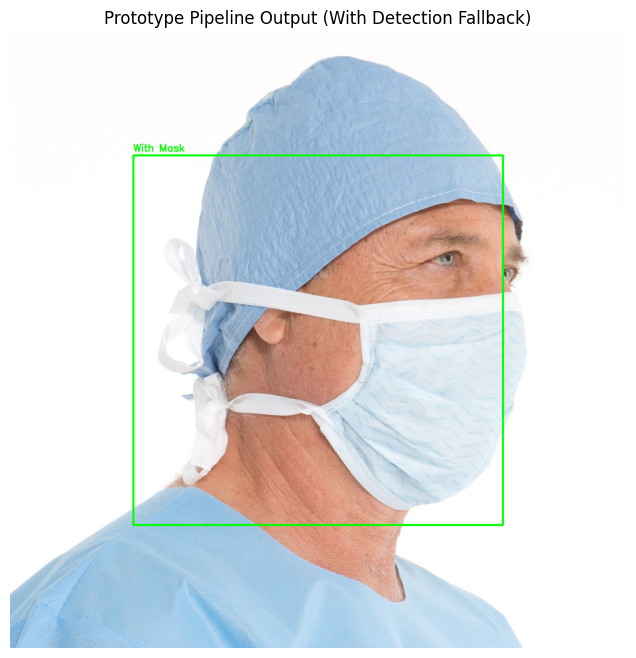

In [ ]:
# Updated end-to-end prototype prediction pipeline with robust fallbacks
def run_face_mask_detector_prototype(raw_image_path=None, direct_image_array=None):
    if raw_image_path is not None:
        img = cv2.imread(str(raw_image_path))
        if img is None:
            print(f"Error: Could not load image from path '{raw_image_path}'")
            return
    else:
        img = direct_image_array.copy()
        
    display_img = img.copy()
    gray = cv2.cvtColor(display_img, cv2.COLOR_BGR2GRAY)
    
    # Running the pre-trained Haar Cascade to locate faces (slightly lowered scaleFactor to increase detection sensitivity)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3, minSize=(30, 30))
    
    # If Haar Cascade fails, create a manual fallback crop region (center 60% of the image)
    if len(faces) == 0:
        print("Haar Cascade missed face detection. Applying manual fallback crop...")
        h, w = gray.shape
        # Calculating a bounding box centered in the middle of the image
        box_w, box_h = int(w * 0.6), int(h * 0.6)
        x = (w - box_w) // 2
        y = (h - box_h) // 2
        faces = np.array([[x, y, box_w, box_h]])
        
    # Iterating through detected faces and classifying
    for (x, y, w, h) in faces:
        # Cropping the face region
        roi = gray[y:y+h, x:x+w]
        
        # Preprocessing the cropped face region: Histogram Equalization, Gaussian Blur, and resizing
        equalized_roi = cv2.equalizeHist(roi)
        blurred_roi = cv2.GaussianBlur(equalized_roi, (5, 5), 0)
        preprocessed_roi = cv2.resize(blurred_roi, (100, 100), interpolation=cv2.INTER_AREA)
        
        # Extracting features
        features = extract_lbp_features(preprocessed_roi)
        features_reshaped = features.reshape(1, -1)
        
        # SVM classification
        prediction = svm_classifier.predict(features_reshaped)[0]
        
        if prediction == 1:
            label_text = "With Mask"
            box_color = (0, 255, 0)   # Green
        else:
            label_text = "Without Mask"
            box_color = (0, 0, 255)   # Red
            
        # Drawing bounding boxes and text labels
        cv2.rectangle(display_img, (x, y), (x + w, y + h), box_color, 3)
        cv2.putText(display_img, label_text, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, box_color, 2)
        
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(display_img, cv2.COLOR_BGR2RGB))
    plt.title("Prototype Pipeline Output (With Detection Fallback)")
    plt.axis('off')
    plt.show()

# testing it on any index (0, 50, or even 100)
test_sample_index = 50
print(f"Testing Prototype System on test image index {test_sample_index}:")
run_face_mask_detector_prototype(direct_image_array=X_test_raw[test_sample_index])

### System Limitation:

Standard Haar Cascade models rely on detecting facial geometry (eyes, nose, mouth) to locate a face. When a mask covers these features, the cascade fails, forcing use of fallback crop boxes that might not capture the face perfectly, degrading classification accuracy.

To resolve this issue, the system should transition to a Deep Learning framework (like a Convolutional Neural Network (CNN)). CNNs learn hierarchical features (combining shape, color, and context) rather than just local micro-textures, making them far more robust to smiles, artificial overlays, and masked faces.
